<h1 style="color: steelblue;">Topic Modeling Assignment</h1>

**Group members:** Qlirim Teneqja, Aylie Nagler, Anika Viado, and Arsi Kharghani

**Assignment number:** 7

**Group number:** 7

<h2 style="color: steelblue;">Executive Summary</h2>


In [18]:
# Imports
import pandas as pd
import re
import html
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation, NMF
from sklearn.manifold import TSNE

import matplotlib.pyplot as plt
import pyLDAvis
import pyLDAvis.lda_model

nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\QTene\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\QTene\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\QTene\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\QTene\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\QTene\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

<h2 style="color: steelblue;">Use Case and Data</h2>

This Project uses topic modeliing to identify recurring themes in reviews of birth-control drugs. the results could help researchers and educators understand which experiences appear in the reviews and identify themes for further investigation. 

We use the provided training and test files from the drug-review dataset. We select records where the condition is "Birth Control" and use the review text for topic modeling. the drug names and ratings provide additional context. 

In [19]:
# Load the files
train_raw = pd.read_csv("UCIdrug_train.csv")
test_raw = pd.read_csv("UCIdrug_test.csv")

# Select birth-control reviews.
train_birth_control = train_raw[
    train_raw["condition"].str.strip().str.casefold().eq("birth control")
].copy()

test_birth_control = test_raw[
    test_raw["condition"].str.strip().str.casefold().eq("birth control")
].copy()

print("Training reviews:", len(train_birth_control))
print("Test reviews:", len(test_birth_control))

display(train_birth_control.head())

Training reviews: 28788
Test reviews: 9648


,uniqueID,drugName,condition,review,rating,date,usefulCount
2,92703,Lybrel,Birth Control,"""I used to take another oral contraceptive, wh...",5,14-Dec-09,17
3,138000,Ortho Evra,Birth Control,"""This is my first time using any form of birth...",8,3-Nov-15,10
9,48928,Ethinyl estradiol / levonorgestrel,Birth Control,"""I had been on the pill for many years. When m...",8,8-Dec-16,1
14,98494,Nexplanon,Birth Control,"""Started Nexplanon 2 months ago because I have...",3,7-Aug-14,10
22,227020,Etonogestrel,Birth Control,"""Nexplanon does its job. I can have worry free...",9,11-Aug-14,11


## Data Inspection

We inspect the selected birth-control reviews for missing values, duplicate rows, and data types before cleaning the data. 

In [20]:
for name, df in [
    ("Training data", train_birth_control),
    ("Test data", test_birth_control),
]:
    print(name)
    df.info()

    print("\nMissing values:")
    print(df.isnull().sum())

    print("\nDuplicate Rows:", df.duplicated().sum())

Training data
<class 'pandas.core.frame.DataFrame'>
Index: 28788 entries, 2 to 161291
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   uniqueID     28788 non-null  int64 
 1   drugName     28788 non-null  object
 2   condition    28788 non-null  object
 3   review       28788 non-null  object
 4   rating       28788 non-null  int64 
 5   date         28788 non-null  object
 6   usefulCount  28788 non-null  int64 
dtypes: int64(3), object(4)
memory usage: 1.8+ MB

Missing values:
uniqueID       0
drugName       0
condition      0
review         0
rating         0
date           0
usefulCount    0
dtype: int64

Duplicate Rows: 0
Test data
<class 'pandas.core.frame.DataFrame'>
Index: 9648 entries, 4 to 53763
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   uniqueID     9648 non-null   int64 
 1   drugName     9648 non-null   object
 2   condition    9

The selected trainin data contains 28,788 birth-control reviews, and the selected test data contains  9,648. Both datasets have seven
columns: `uniqueID`, `drugName`, `condition`, `review`, `rating`,
`date`, and `usefulCount`.

Neither dataset contains missing values or exact duplicate rows.
The review text is stored as an object data type and will be used for
topic modeling. The date is also stored as text, but it does not need
to be converted because it is not needed for the planned topic models.

## Preparing Review Text

We separate the review text from the remaining columns so it can be cleaned and preprocessed for topic modeling. the original selected dataframes are preserved for reference.

In [21]:
train_reviews = train_birth_control["review"].copy()
test_reviews = test_birth_control["review"].copy()

print("Training reviews:", len(train_reviews))
print("Test reviews:", len(test_reviews))

display(train_reviews.head())

Training reviews: 28788
Test reviews: 9648


2     "I used to take another oral contraceptive, wh...
3     "This is my first time using any form of birth...
9     "I had been on the pill for many years. When m...
14    "Started Nexplanon 2 months ago because I have...
22    "Nexplanon does its job. I can have worry free...
Name: review, dtype: object

In [22]:
# Check for empty reviews or that contain whitespaces
print(
    "Blank training reviews:",
    train_birth_control["review"].str.strip().eq("").sum()
)

print(
    "Blank test reviews:",
    test_birth_control["review"].str.strip().eq("").sum()
)

Blank training reviews: 0
Blank test reviews: 0


Neither the training nor the test data contains blank reviews.
No reviews needed to be removed based on the missing-value,
blank-value, or exact-duplicate checks.

## Rating Distribution

The ratings are not labels for the topic models, but their distribution provides context about the birth control reviews in the training data

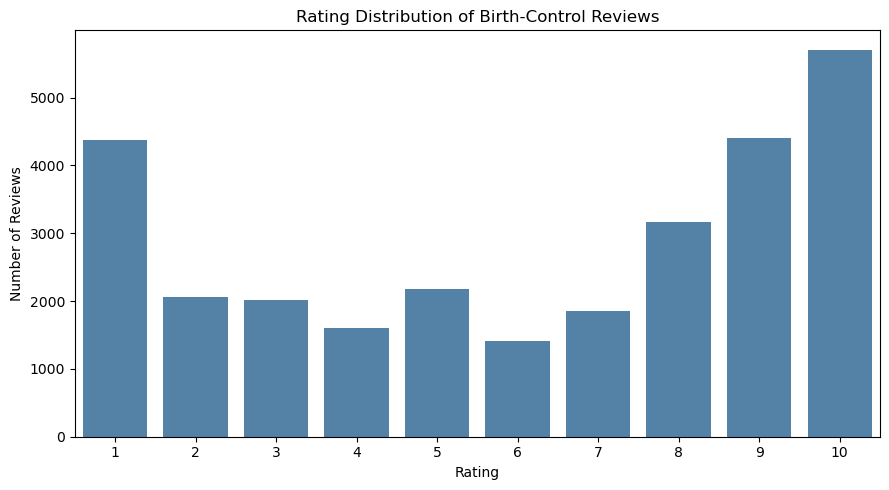

rating
1     4383
2     2065
3     2019
4     1610
5     2174
6     1415
7     1847
8     3165
9     4402
10    5708
Name: count, dtype: int64


In [23]:
# Count training reviews for each rating.
rating_counts = train_birth_control["rating"].value_counts().sort_index()

# Plot the counts.
plt.figure(figsize=(9, 5))
sns.barplot(x=rating_counts.index, y=rating_counts.values, color="steelblue")
plt.title("Rating Distribution of Birth-Control Reviews")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

print(rating_counts)

The ratings are unevenly distributed. the most common rating is 10 with 5,708 reviews, while the least common rating is 6, with 1415 reviews. Ratings of 1 and 9 are also common, with 4, 383 and 4,402 reviews respectively.

This hows that the training data incoudes many reviewss at both the high and low ends of the rating scale. ratings provide context for the reviews but are not used as labels for the topic models.

<h2 style="color: steelblue;">Preprocessing</h2>



<h2 style="color: steelblue;">Models</h2>



<h3 style="color: steelblue;">Text Vectorization</h3>

<h3 style="color: steelblue;">Latent Dirichlet Allocation (LDA) Models</h3>


<h3 style="color: steelblue;">Non-negative Matrix Factorization (NMF) Models</h3>



<h3 style="color: steelblue;">Iterations and Model Selection</h3>


<h2 style="color: steelblue;">Discussion</h2>

<h3 style="color: steelblue;">Best LDA and NMF Results</h3>



<h3 style="color: steelblue;">LDA Visualizations</h3>


<h3 style="color: steelblue;">Comparison and Interpretation</h3>



<h2 style="color: steelblue;">Conclusion</h2>


<h2 style="color: steelblue;">Acknowledgment of Contributions</h2>


- **Qlirim Teneqja:** [Contributions; awareness and understanding]
- **Aylie Nagler:** [Contributions; awareness and understanding]
- **Anika Viado:** [Contributions; awareness and understanding]
- **Arsi Kharghani:** [Contributions; awareness and understanding]